In [42]:
import numpy as np
import pandas as pd
import yfinance as yf
from arch import arch_model
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf



[*********************100%***********************]  1 of 1 completed


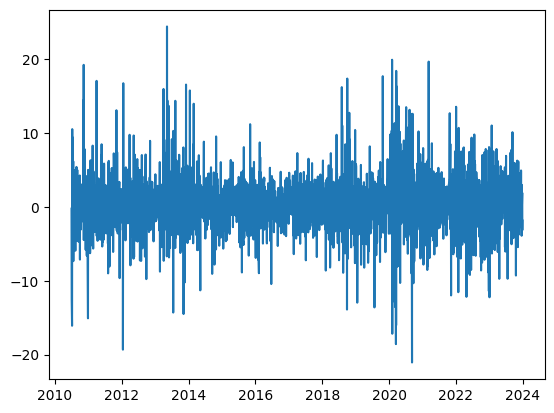

In [43]:

symbol = 'TSLA'
start_date = '2010-01-01'
end_date = '2024-01-01'

data = yf.download(symbol, start=start_date, end=end_date)
data['returns'] = 100* data['Adj Close'].pct_change()
data = data.dropna()
data['realized_volatility'] = data['returns'].rolling(window=100).std()
# data.head()
plt.plot(data['returns'])



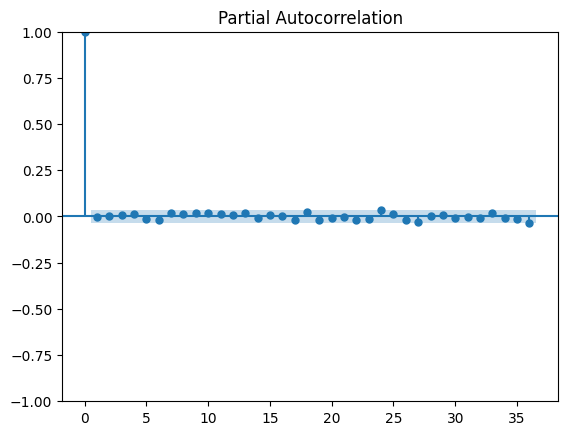

In [44]:
plot_pacf(data['returns'],alpha = 0.05)
plt.show()

In [45]:
model = arch_model(data['returns'], vol='GARCH', p=1, q=1)
model_fit = model.fit(disp='off')
print (model_fit.params)
print(model_fit.summary())

mu          0.172016
omega       0.135267
alpha[1]    0.031410
beta[1]     0.957635
Name: params, dtype: float64
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -8973.27
Distribution:                  Normal   AIC:                           17954.5
Method:            Maximum Likelihood   BIC:                           17979.1
                                        No. Observations:                 3399
Date:                Thu, Dec 26 2024   Df Residuals:                     3398
Time:                        02:32:52   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------

In [40]:
forecasts = []
window = 200
for i in range(window,len(data)):
  model = arch_model(data['returns'].iloc[i-window:i], vol='GARCH', p=1, q=1)
  model_fit = model.fit(disp='off')
  forecast = model_fit.forecast(horizon=1)
  forecasts.append(forecast.variance.iloc[-1, 0])
forecast_series = pd.Series(forecasts, index=data['returns'].index[window:])
print (forecast_series)




Date
2020-10-19    20.004822
2020-10-20    20.157374
2020-10-21    20.164746
2020-10-22    17.984997
2020-10-23    16.044924
                ...    
2023-12-22     8.191720
2023-12-26     9.232397
2023-12-27     9.249489
2023-12-28     7.793438
2023-12-29     9.195529
Length: 805, dtype: float64


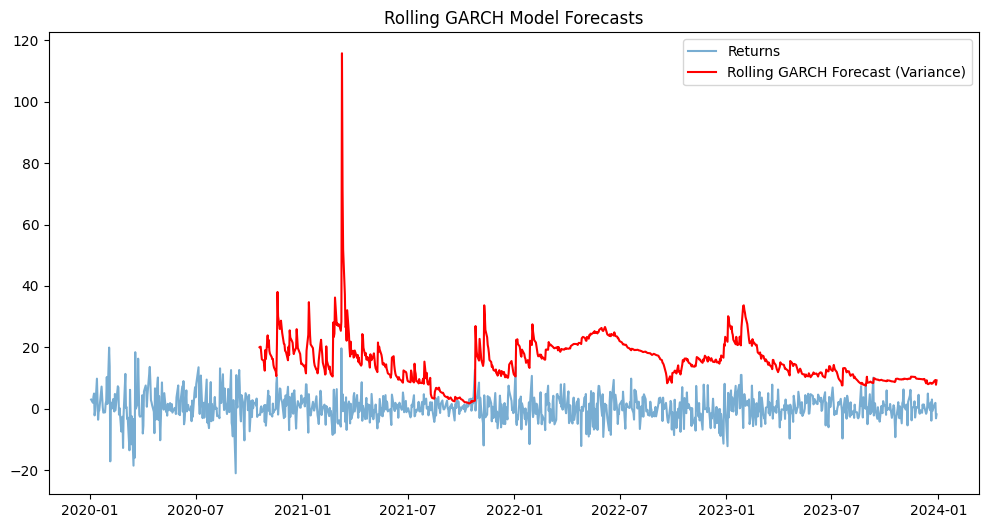

In [41]:
plt.figure(figsize=(12, 6))
plt.plot(data['returns'], label="Returns", alpha=0.6)
plt.plot(forecast_series, label="Rolling GARCH Forecast (Variance)", color="red")
plt.legend()
plt.title("Rolling GARCH Model Forecasts")
plt.show()